In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ratings = pd.read_csv(
    "../data/processed/ratings_clean.csv",
    dtype={"user_id": "int32", "movie_id": "int16", "rating": "int8"},
)
print(ratings.shape)
ratings.head()

(22319353, 4)


,user_id,movie_id,rating,date
0,1488844,1,3,2005-09-06
1,822109,1,5,2005-05-13
2,885013,1,4,2005-10-19
3,30878,1,4,2005-12-26
4,823519,1,3,2004-05-03


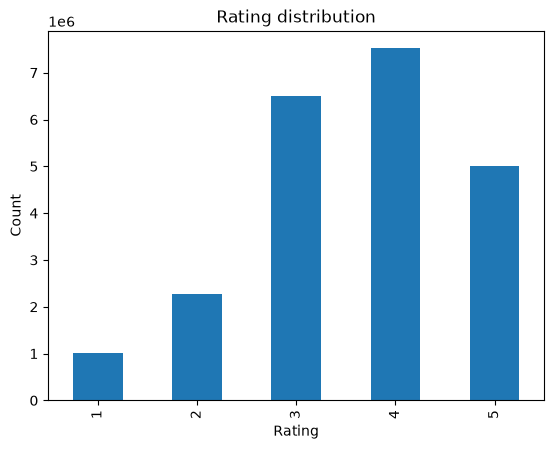

In [2]:
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

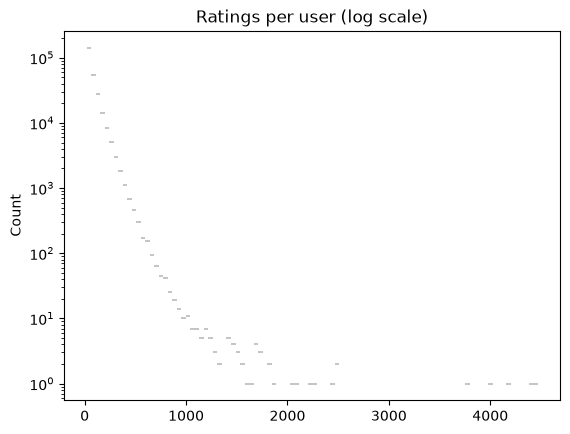

count    260506.000000
mean         85.676925
std          85.465971
min          20.000000
25%          34.000000
50%          58.000000
75%         106.000000
max        4467.000000
dtype: float64


In [3]:
ratings_per_user = ratings.groupby("user_id").size()
sns.histplot(ratings_per_user, bins=100, log_scale=(False, True))
plt.title("Ratings per user (log scale)")
plt.show()
print(ratings_per_user.describe())

In [4]:
movie_stats = ratings.groupby("movie_id")["rating"].agg(["count", "mean"])
print(movie_stats.nlargest(10, "count"))
print(movie_stats["count"].describe())

           count      mean
movie_id                  
1905      171309  4.152356
3860      140284  3.428723
571       139320  3.956632
2452      138778  4.437029
4432      136108  3.742984
4306      135189  4.318155
3938      133303  4.137041
3962      127661  4.409890
1962      125177  3.747621
2152      124756  3.419058
count      4499.000000
mean       4960.958657
std       14584.699347
min          29.000000
25%         176.000000
50%         508.000000
75%        2403.500000
max      171309.000000
Name: count, dtype: float64


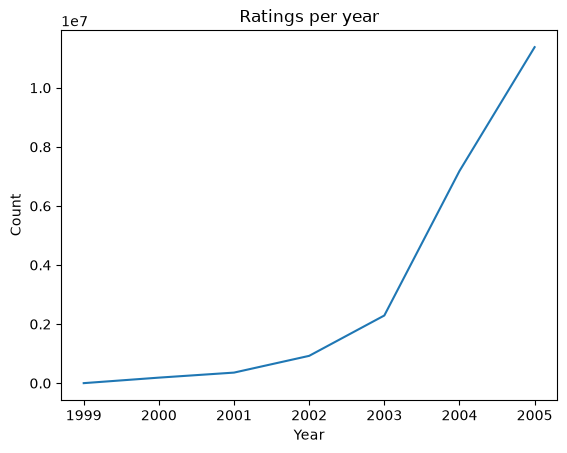

In [5]:
years = ratings["date"].str[:4].astype(int)
years.value_counts().sort_index().plot(title="Ratings per year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

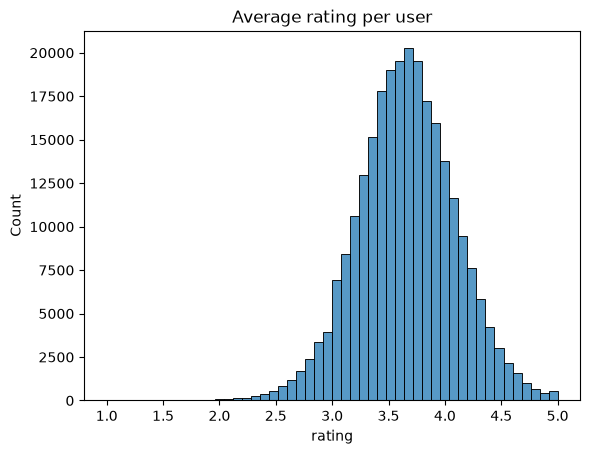

In [6]:
user_mean = ratings.groupby("user_id")["rating"].mean()
sns.histplot(user_mean, bins=50)
plt.title("Average rating per user")
plt.show()

In [7]:
%%time
from surprise import Dataset, Reader, SVD, BaselineOnly, accuracy
from surprise.model_selection import train_test_split

sample_users = ratings["user_id"].drop_duplicates().sample(n=20000, random_state=42)
small = ratings[ratings["user_id"].isin(sample_users)]
print(len(small), "ratings in sample")

reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(small[["user_id", "movie_id", "rating"]], reader)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
print(trainset.n_users, "users,", trainset.n_items, "movies,", trainset.n_ratings, "training ratings")
print(len(testset), "test ratings")

1713012 ratings in sample
20000 users, 4492 movies, 1370409 training ratings
342603 test ratings
CPU times: total: 6.33 s
Wall time: 6.54 s


In [8]:
%%time
svd = SVD(n_factors=50, n_epochs=10, lr_all=0.005, reg_all=0.02, random_state=42)
svd.fit(trainset)
svd_preds = svd.test(testset)
print("SVD RMSE:", accuracy.rmse(svd_preds, verbose=False))
print("SVD MAE:", accuracy.mae(svd_preds, verbose=False))

SVD RMSE: 0.9010868932264151
SVD MAE: 0.7052020880042373
CPU times: total: 11.2 s
Wall time: 11.3 s


In [9]:
%%time
baseline = BaselineOnly()
baseline.fit(trainset)
base_preds = baseline.test(testset)
print("Baseline RMSE:", accuracy.rmse(base_preds, verbose=False))
print("Baseline MAE:", accuracy.mae(base_preds, verbose=False))

Estimating biases using als...
Baseline RMSE: 0.9221272625764999
Baseline MAE: 0.7261835462420431
CPU times: total: 5.77 s
Wall time: 5.86 s


In [10]:
%%time
svd = SVD(n_factors=50, n_epochs=10, lr_all=0.005, reg_all=0.02, random_state=42)
svd.fit(trainset)
svd_preds = svd.test(testset)
print("SVD RMSE:", accuracy.rmse(svd_preds, verbose=False))
print("SVD MAE:", accuracy.mae(svd_preds, verbose=False))

SVD RMSE: 0.9010868932264151
SVD MAE: 0.7052020880042373
CPU times: total: 9.86 s
Wall time: 9.96 s


In [11]:
%%time
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=4.0):
    user_preds = defaultdict(list)
    for p in predictions:
        user_preds[p.uid].append((p.est, p.r_ui))
    precisions, recalls = [], []
    for pairs in user_preds.values():
        pairs.sort(key=lambda x: x[0], reverse=True)
        top_k = pairs[:k]
        n_rel = sum(r >= threshold for _, r in pairs)
        n_rel_k = sum(r >= threshold for _, r in top_k)
        precisions.append(n_rel_k / k)
        if n_rel:
            recalls.append(n_rel_k / n_rel)
    return sum(precisions) / len(precisions), sum(recalls) / len(recalls)

svd_p, svd_r = precision_recall_at_k(svd_preds, k=10)
base_p, base_r = precision_recall_at_k(base_preds, k=10)
print(f"Baseline  Precision@10: {base_p:.3f}  Recall@10: {base_r:.3f}")
print(f"SVD       Precision@10: {svd_p:.3f}  Recall@10: {svd_r:.3f}")

Baseline  Precision@10: 0.558  Recall@10: 0.785
SVD       Precision@10: 0.565  Recall@10: 0.790
CPU times: total: 1.56 s
Wall time: 1.6 s


In [12]:
import pandas as pd

def recommend(user_id, model, known_df, n=10):
    seen = set(known_df.loc[known_df["user_id"] == user_id, "movie_id"])
    candidates = [m for m in known_df["movie_id"].unique() if m not in seen]
    preds = [model.predict(user_id, m) for m in candidates]
    top = sorted(preds, key=lambda p: p.est, reverse=True)[:n]
    return pd.DataFrame({
        "movie_id": [p.iid for p in top],
        "predicted_rating": [round(p.est, 2) for p in top],
    })

sample_user = small["user_id"].iloc[0]
print("Recommendations for user", sample_user)
print(recommend(sample_user, svd, small))

Recommendations for user 1248029
   movie_id  predicted_rating
0      3456              4.23
1      1947              4.16
2        32              4.14
3      1917              4.11
4      3958              4.11
5      2114              4.11
6      3928              4.10
7       774              4.06
8      3965              4.03
9      2102              4.03


In [13]:
rated = set(small.loc[small["user_id"] == sample_user, "movie_id"])
recs = recommend(sample_user, svd, small)
overlap = rated & set(recs["movie_id"])
print("Movies rated by user:", len(rated))
print("Overlap with recommendations (should be empty):", overlap)

Movies rated by user: 338
Overlap with recommendations (should be empty): set()
